# Prediccion por Regresion Lineal - Consumo de Combustible

Usamos dataset automoviles, sus caracteristicas y variable objetivo de consumo de combustible

Fuente:

Pendiente: -0.1626
Intercepto: 40.6061
MAE:  3.78
RMSE: 4.71
R²:   0.5660


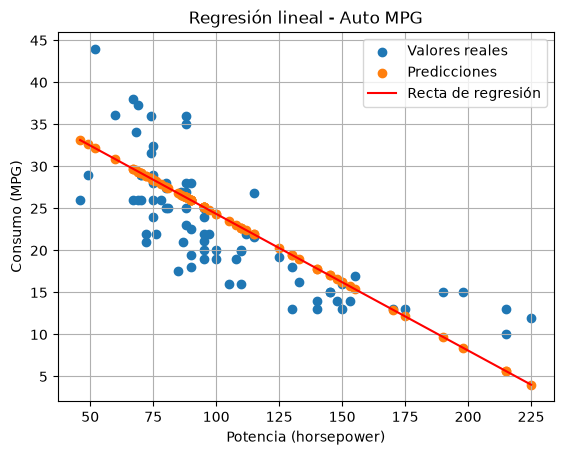

Consumo estimado para 100 HP: 24.35 MPG


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Cargar el dataset Auto MPG
url = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
)

columnas = [
    "mpg", "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year", "origin", "car_name"
]

df = pd.read_csv(
    url,
    sep=r"\s+",
    names=columnas,
    na_values="?"
)

# 2. Limpiar los datos
df = df.dropna(subset=["mpg", "horsepower"])

# 3. Definir variables predictora (X) y objetivo (y)
X = df[["horsepower"]]
y = df["mpg"]

# 4. Dividir los datos: 80% entrenamiento, 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. Entrenar el modelo
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# 6. Realizar predicciones
y_pred = modelo.predict(X_test)

# 7. Evaluar el modelo
print(f"Pendiente: {modelo.coef_[0]:.4f}")
print(f"Intercepto: {modelo.intercept_:.4f}")
print(f"MAE:  {mean_absolute_error(y_test, y_pred):.2f}")
print(f"RMSE: {mean_squared_error(y_test, y_pred) ** 0.5:.2f}")
print(f"R²:   {r2_score(y_test, y_pred):.4f}")

# 8. Visualizar los datos y la recta de regresión
plt.scatter(X_test["horsepower"], y_test, label="Valores reales")
plt.scatter(X_test["horsepower"], y_pred, label="Predicciones")

orden = X_test["horsepower"].sort_values()
plt.plot(
    orden,
    modelo.predict(orden.to_frame()),
    color="red",
    label="Recta de regresión"
)

plt.xlabel("Potencia (horsepower)")
plt.ylabel("Consumo (MPG)")
plt.title("Regresión lineal - Auto MPG")
plt.legend()
plt.grid(True)
plt.show()

# 9. Predecir el consumo de un automóvil de 100 HP
nuevo_auto = pd.DataFrame({"horsepower": [100]})
prediccion = modelo.predict(nuevo_auto)

print(f"Consumo estimado para 100 HP: {prediccion[0]:.2f} MPG")
